### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [468]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [469]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics


### Examples of how to filter wandb runs:

example_filters = {


    "group" : "17/5 single-bi-trimodal",
    "config.image_encoder.use": True,
    "config.batch_size": {'$gt': 10}, #Greater than
    "config.batch_size": {'$lte': 10}, #Less than or equal
    
	"$and": [{
		'created_at': {
			"$lt": '2022-03-09T10',
			"$gt": '2022-03-07T17'
		}
	}]
    
}

In [470]:
# Define the filter criteria
'''filter_criteria = {
    'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    
    "group" : "25/5 eval freezing enc, modalities, n of examples",
    "config.seed" : 420,
    "$or": [{
        'config.train_examples_per_class': {
            "$gt": '200',
        }
    },
        {
        'config.train_examples_per_class': {
            "$lt": '200',
        }
    }
    ]
}'''


'filter_criteria = {\n    \'config.image_encoder.use\': True,\n    #\'config.tabular_encoder.use\': True,\n    #\'config.loc_encoder.use\': True,\n    \n    "group" : "25/5 eval freezing enc, modalities, n of examples",\n    "config.seed" : 420,\n    "$or": [{\n        \'config.train_examples_per_class\': {\n            "$gt": \'200\',\n        }\n    },\n        {\n        \'config.train_examples_per_class\': {\n            "$lt": \'200\',\n        }\n    }\n    ]\n}'

In [471]:
# Define the filter criteria
filter_criteria = {
    #'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    

    #"group" : "5/8 test set one image",
    #"group" : "8/8 test set one image",
    "group" : "9/8 test set four images",
    #"config.seed" : 420,
    #"$and": [{
    #'created_at': {
    #        "$lt": '2024-06-24T00',
    #        "$gt": '2024-06-01T17'
    #    }
    #}]

    
}





In [472]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 309


In [432]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#models = [model for model in models  if model['config']['seed'] == 422]  
#print(len(selected_models))
#models = selected_models

In [473]:
print(len(models))

309


In [474]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12


In [482]:
CHECKPOINT_TYPE = 'last'

for i, model_dict in enumerate(tqdm.tqdm(models)):
    if i < 225:
        continue
        
    try:
        metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
    except:
        continue
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = None
    #try:
    #    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])
    #    model_dict['summary']['val conf matrix'] = None
    #    model_dict['summary']['train conf matrix'] = None
    #except KeyError:
    #    pass
    

100%|█████████████████████████████████████████| 309/309 [09:18<00:00,  1.81s/it]


In [479]:
model_dict

{'config': {'seed': 421,
  'epochs': 50,
  'batch_size': 64,
  'classifier': {'type': 'transformer',
   'attention_heads': 8,
   'transformer_layers': 3},
  'in_channels': 4,
  'loc_encoder': {'use': True, 'positional_embedding': 'cartesian3d'},
  'n_parameters': 13158668,
  'val_dst_size': 5018,
  'weight_decay': 0.002,
  'embedding_dim': 128,
  'image_encoder': {'use': True,
   'type': 'cnn',
   'backbone': 'resnet18',
   'freeze_after': 30,
   'moco_weights': False,
   'learning_rate': 0.001,
   'pretrained_backbone': True},
  'learning_rate': 0.0005,
  'model_version': 'v1',
  'token_dropout': 0,
  'folds_to_split': {'column': 'split',
   'mapping': {'0': 'train',
    '1': 'train',
    '2': 'train',
    '3': 'train',
    '4': 'val'}},
  'train_dst_size': 1000,
  'use_forestloss': True,
  'tabular_encoder': {'use': False,
   'type': 'token',
   'dataset': 'deduce',
   'dropout': 0.2,
   'temporal_processing': 'dynamic'},
  'randomize_labels': False,
  'forestloss_params': {'sigma': 

In [476]:
print(i)

225


In [360]:
##### selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


In [399]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [ ]:

#filename = '26_7_eval_on_test_set'

#filename = '29_7_eval_on_test_set'
#filename_2 = '30_7_eval_on_test_set'
#filename = '30_7_eval_on_test_set_seed_422to425'
#filename = '5_8_eval_on_test_set_one_img'
#filename = '8_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_one_img'
filename = '9_8_eval_on_test_set_four_img'


In [ ]:
with open(f'{filename}.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:


with open(f'{filename}.pickle', 'rb') as handle:
    other_models = pickle.load(handle)


In [440]:
len(other_models)

280

In [404]:
models = other_models + models

In [157]:
#models = [model for model in other_models  if model['config']['two_model_regularization']['use'] == False]
#models = [model for model in models  if model['config']['model_version'] == 'v1']




In [364]:
len(models)

64

In [442]:
import importlib
importlib.reload(utils)


<module 'utils' from '/home/jan/Documents/EPFL/project_2/notebooks/../utils.py'>

In [443]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [444]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'loc_encoder': {'use': [False, True]},
 'image_encoder': {'use': [False, True]},
 'tabular_encoder': {'use': [False, True]},
 'train_dataset_total_size': [20000, 100, 5000, 1000, 200, 10000, 2000, 500]}

In [445]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split_no_masolele.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [446]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [447]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [448]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [449]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 20000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 100, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 5000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 200, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000, 'seed': 425}
no metrics for: 

In [413]:
#performance_per_configuration = {key:value for key, value in performance_per_configuration.items() if "{'model_version': 'v2', 'tabular_encoder': {'use': False}" not in key}


In [450]:
list(performance_per_configuration.keys())

["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 20000}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 100}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 5000}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 1000}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 200}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 2000}",
 "{'image_encoder': {'use': False}, 'loc_

In [451]:
models_100_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 100}" in key}
models_200_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 200}" in key}
models_500_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 500}" in key}
models_1000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 1000}" in key}
models_2000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 2000}" in key}
models_5000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 5000}" in key}
models_10000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 10000}" in key}
models_20000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 20000}" in key}


In [452]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

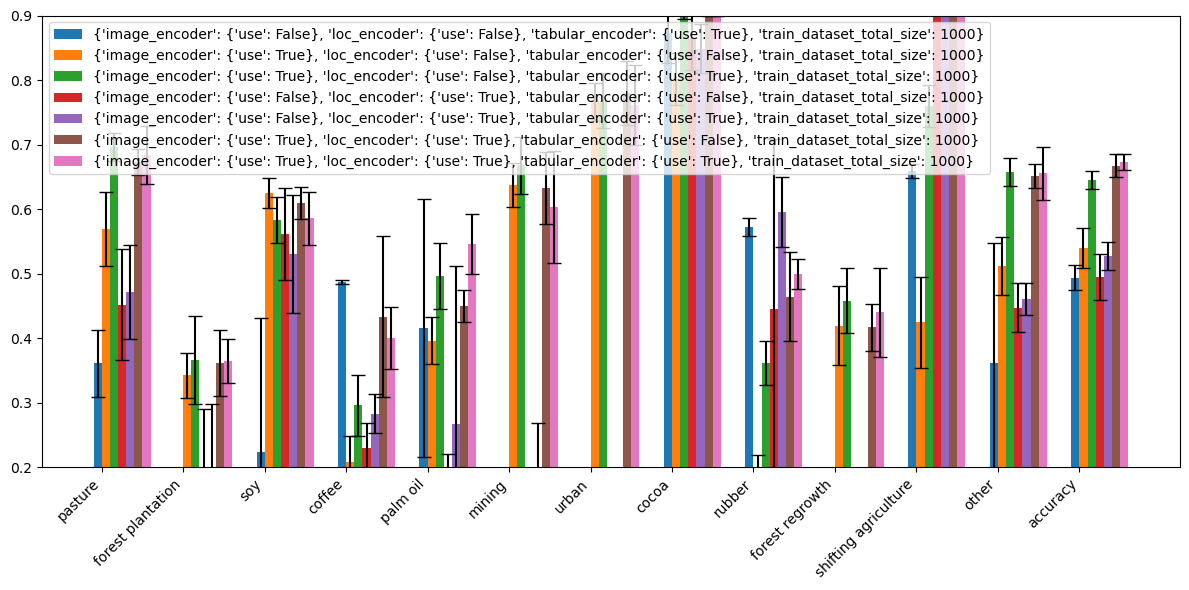

In [465]:
plot_metrics(models_1000_dst, ylim=(0.2, 0.9))

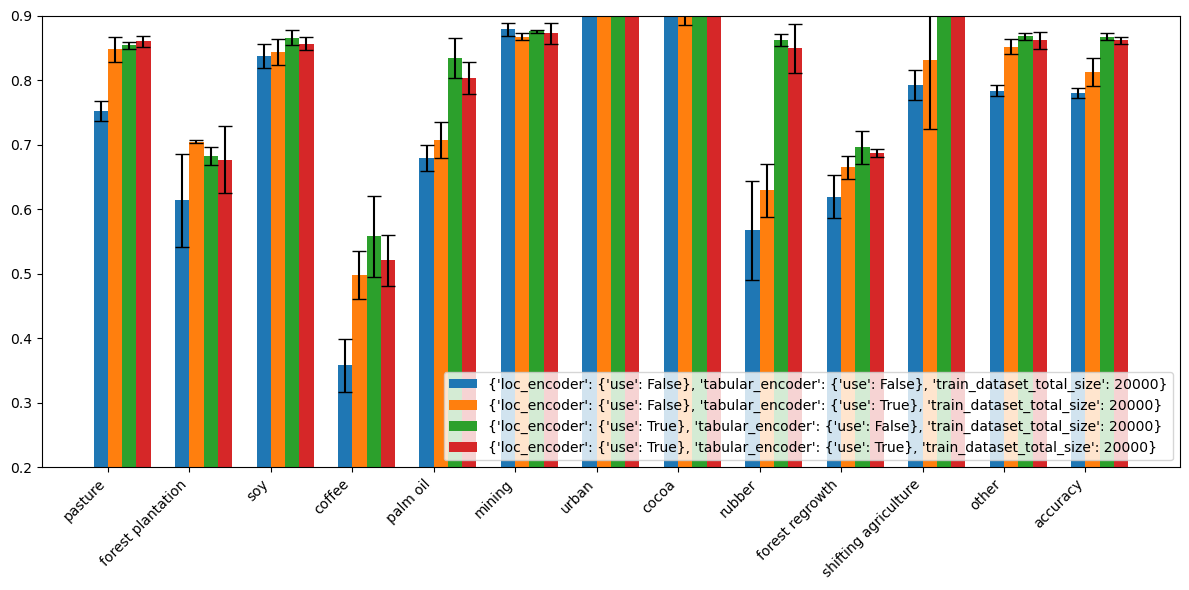

In [426]:
plot_metrics(models_20000_dst, ylim=(0.2, 0.9))

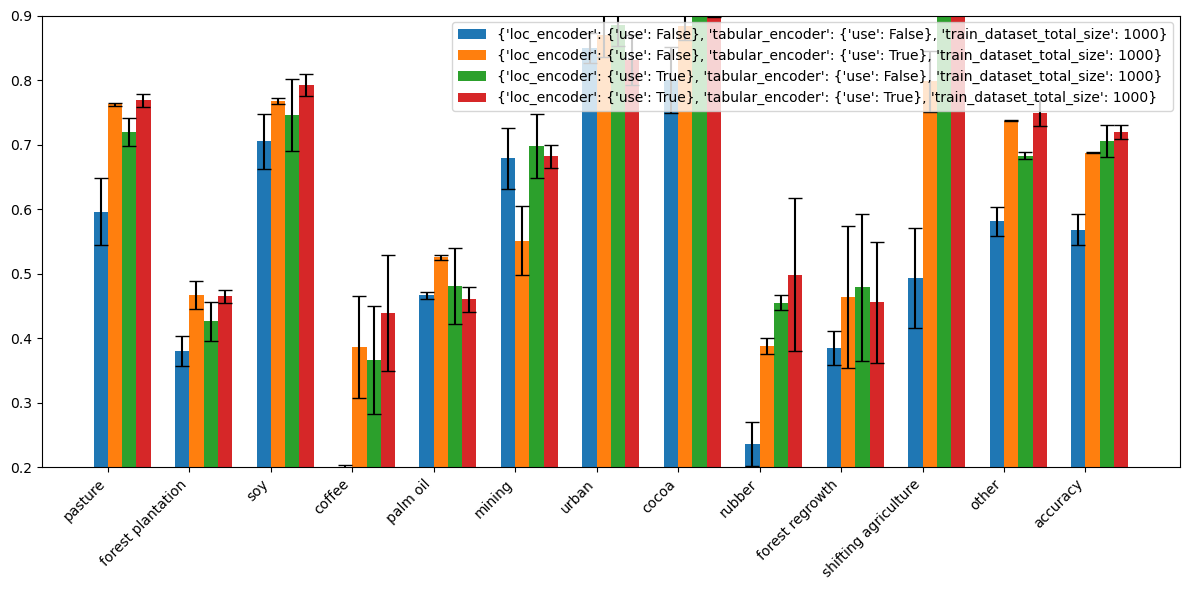

In [389]:

plot_metrics(models_1000_dst, ylim=(0.2, 0.9))

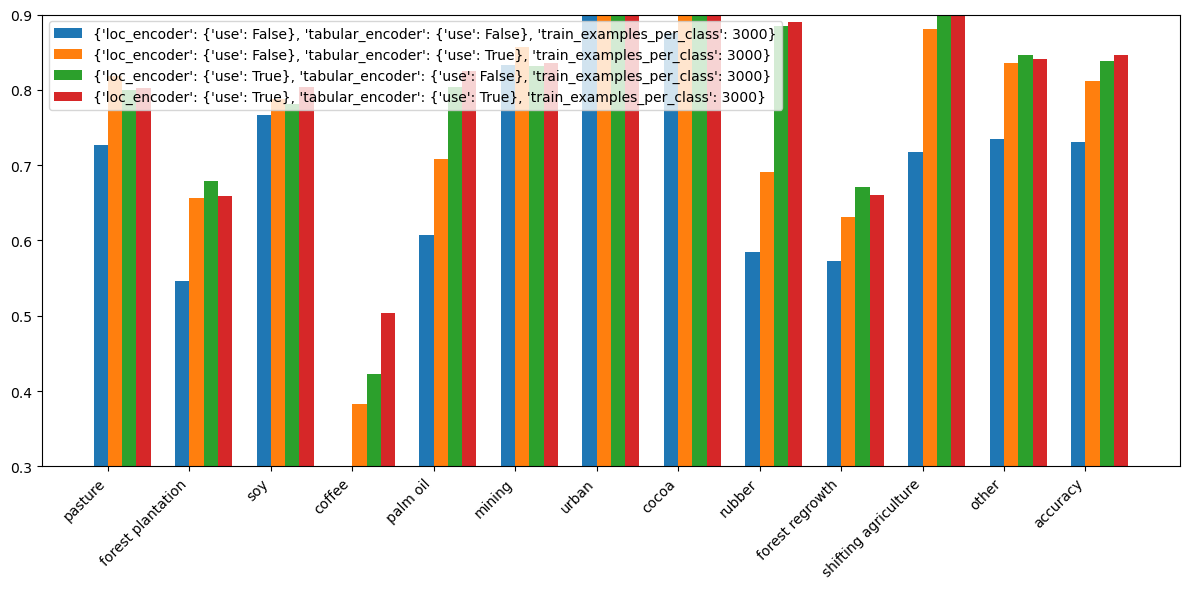

In [329]:
plot_metrics(models_3000_per_class, ylim=(0.3, 0.9))

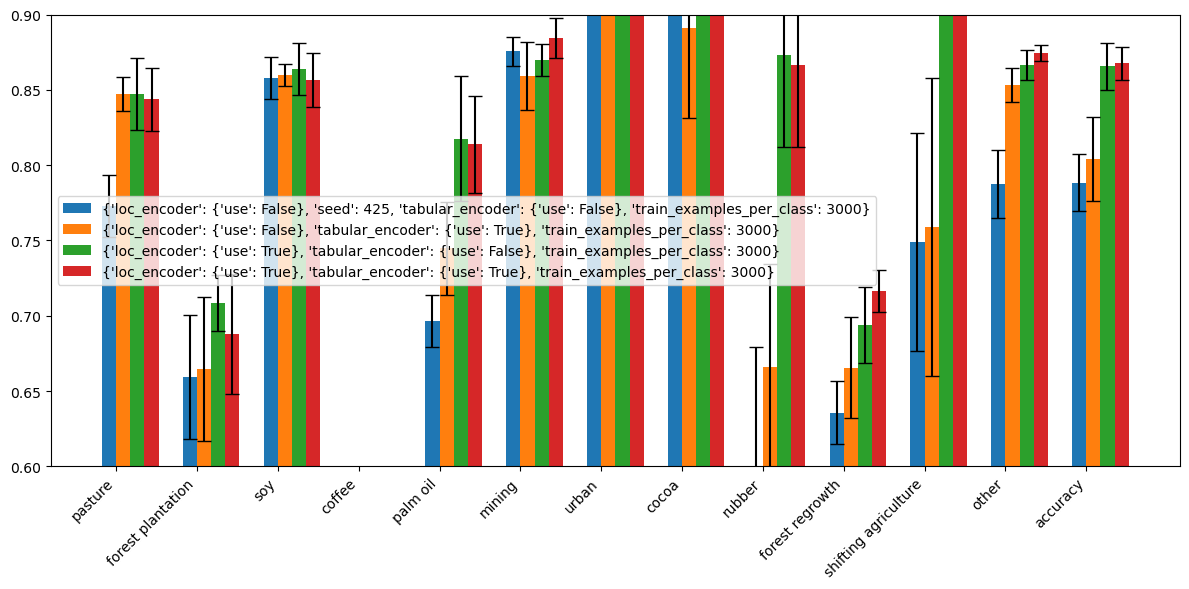

In [193]:
plot_metrics(models_3000_per_class, ylim=(0.6, 0.9))

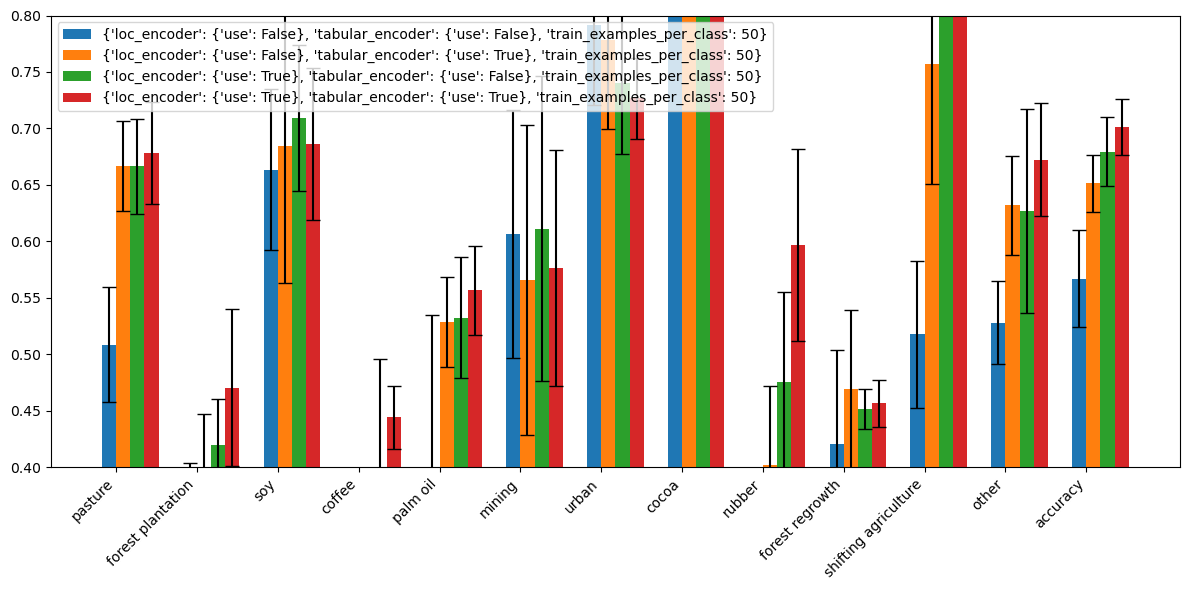

In [121]:
plot_metrics(models_50_per_class, ylim=(0.4, 0.8))

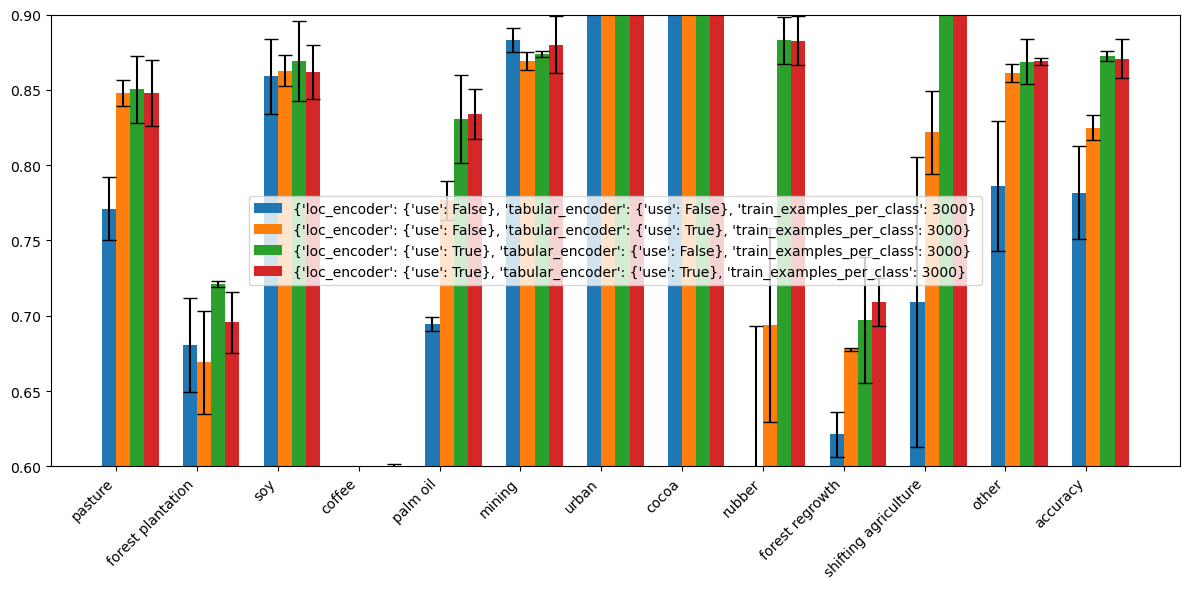

In [48]:
plot_metrics(models_3000_per_class, ylim=(0.6, 0.9))

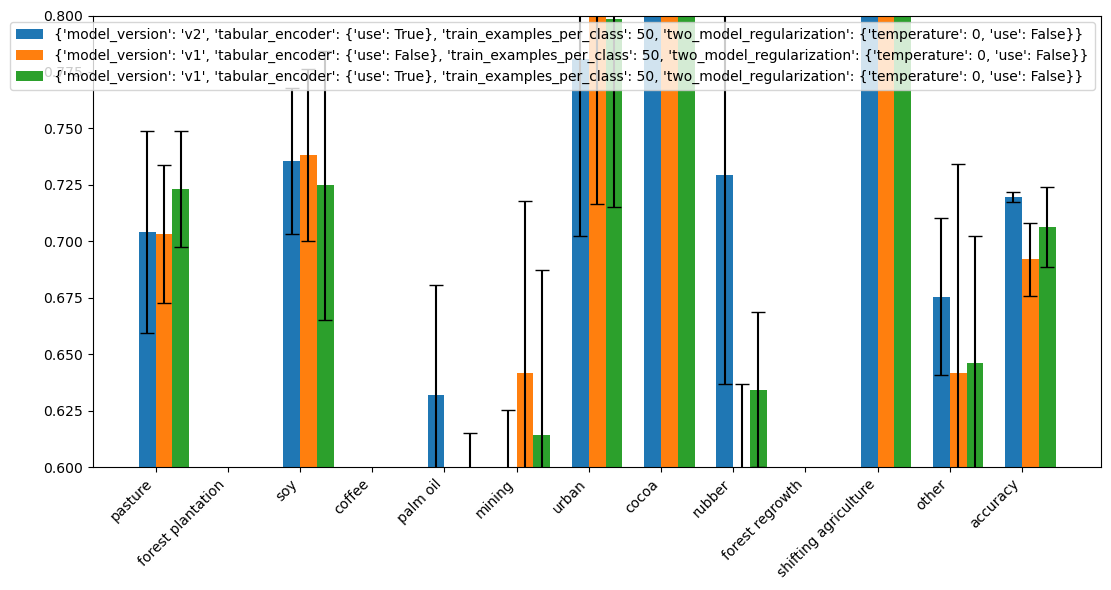

In [115]:
plot_metrics(models_50_per_class, ylim=(0.6, 0.8))

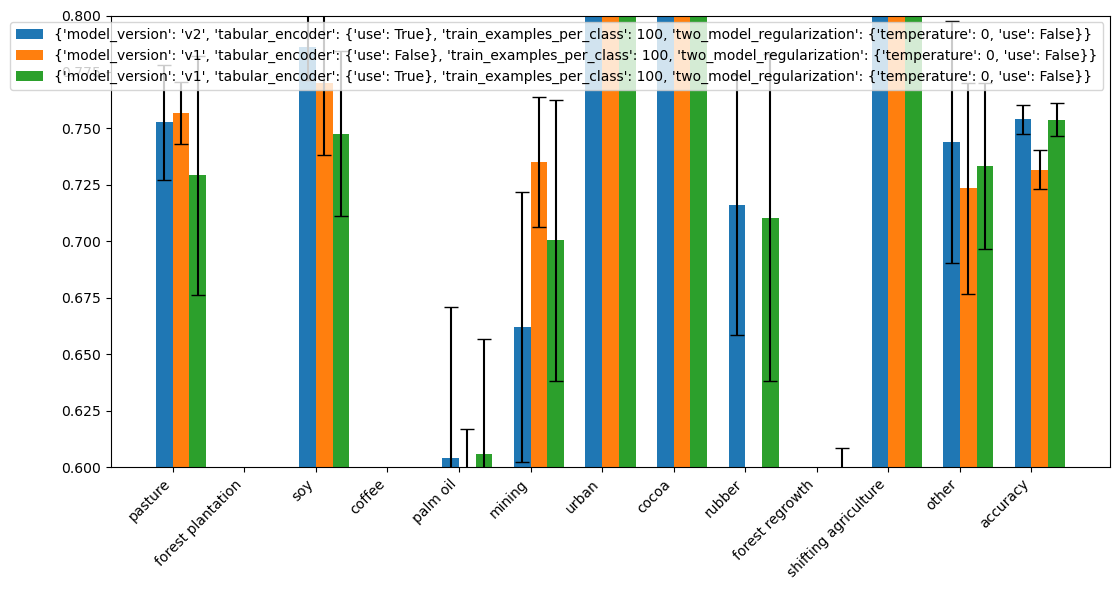

In [116]:
plot_metrics(models_100_per_class, ylim=(0.6, 0.8))

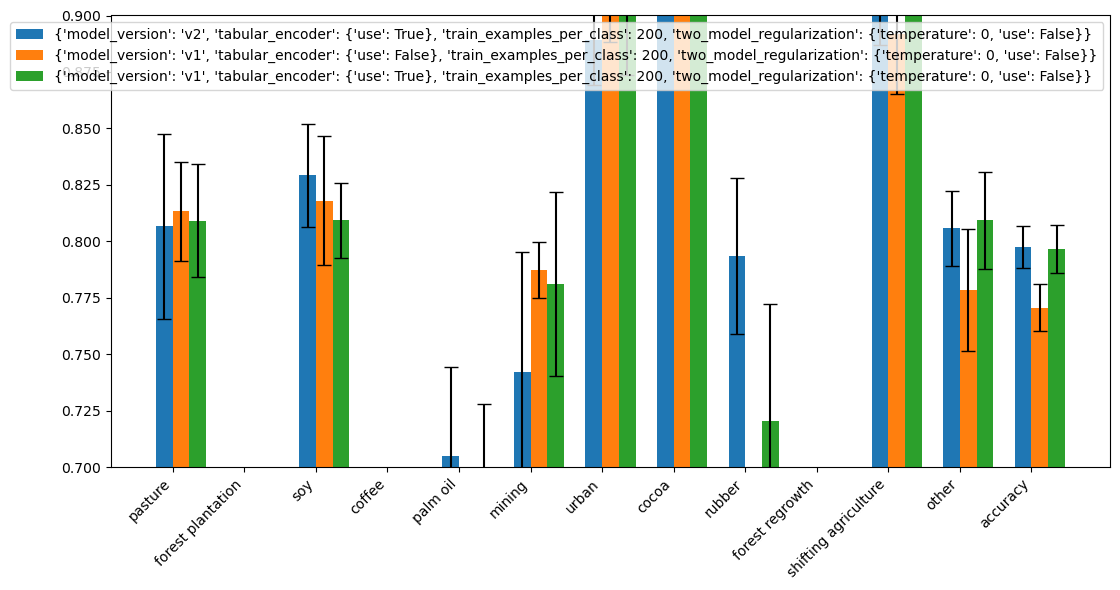

In [117]:
plot_metrics(models_200_per_class, ylim=(0.7, 0.9))

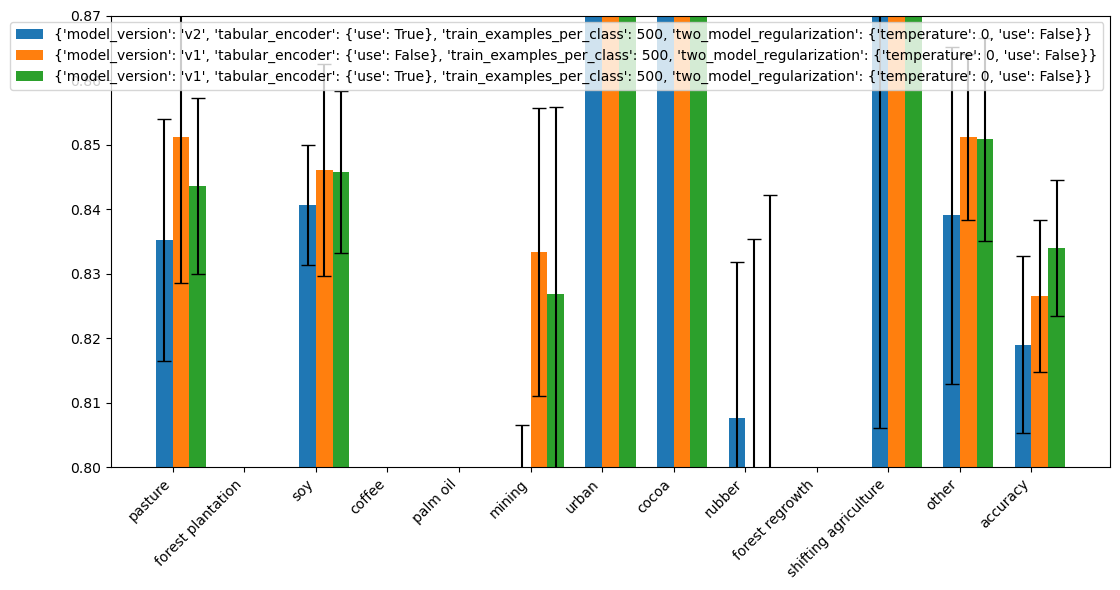

In [118]:
plot_metrics(models_500_per_class, ylim=(0.8, 0.87))

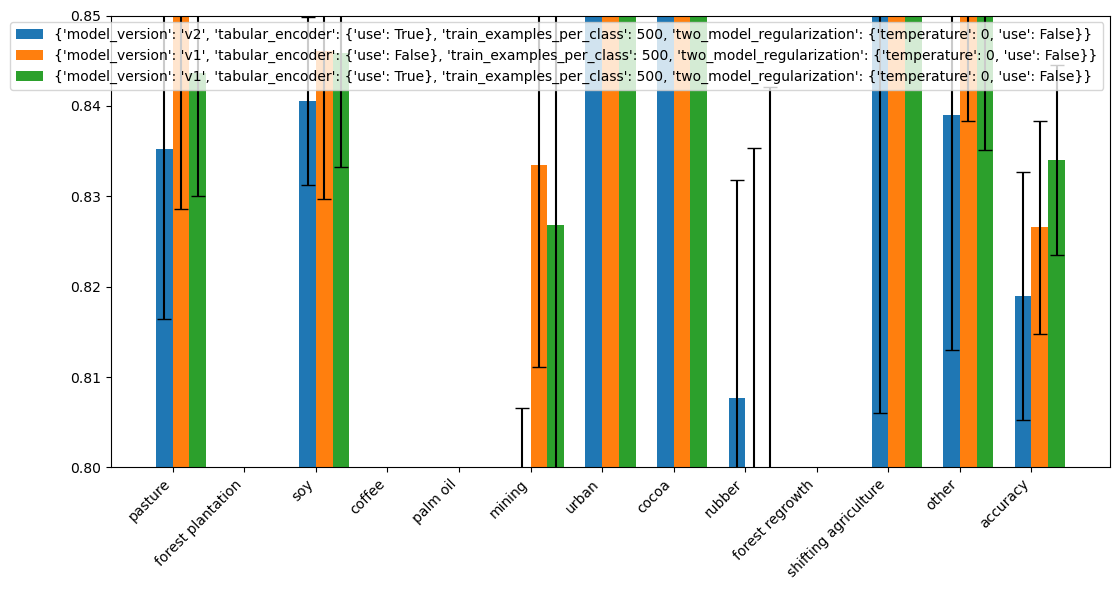

In [119]:
plot_metrics(models_1000_per_class, ylim=(0.8, 0.85))

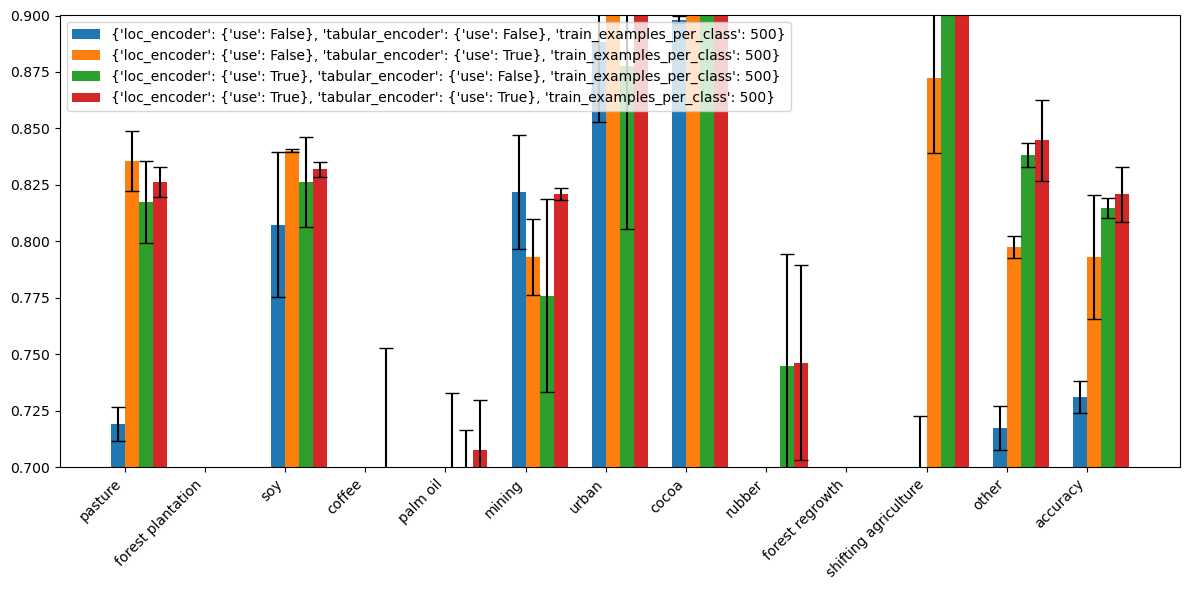

In [62]:
plot_metrics(models_1000_per_class, ylim=(0.7, 0.9))

In [72]:
models_1000_per_class.keys()

dict_keys(["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 500}", "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 500}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 500}", "{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 500}"])

In [ ]:
"{'tabular_encoder': {'use': False}, 'train_examples_per_class': 20}"
"{'tabular_encoder': {'use': False}, 'train_examples_per_class': 20}"

In [194]:
list(performance_per_configuration.keys())

["{'loc_encoder': {'use': False}, 'seed': 420, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 1000}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 50}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 500}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 20}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 3000}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 100}",
 "{'loc_encoder': {'use': False}, 'seed': 425, 'tabular_encoder':

In [ ]:
import ast
import re


# Function to remove 'seed' key-value pairs from a string representation of a dictionary
def remove_seed(entry):
    # Remove the seed key-value pair using regular expressions
    cleaned_entry = re.sub(r"'seed': \d+,? ?", "", entry)
    return cleaned_entry

In [200]:
performance_per_configuration_renamed = {}

for key, value in performance_per_configuration.items():
    performance_per_configuration_renamed[remove_seed(key)] = value
    

In [270]:
def process_stats_all(___models, metric='accuracy'):

    _models_stats = {}
    
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in [20, 50, 100, 200, 500, 1000, 3000]:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_examples_per_class': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_examples_per_class': {n_examples}") 
            sel_model = selected_models[model_name]
            acc = sel_model['mean'][metric]['f1-score']
            std = sel_model['std'][metric]['f1-score']
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)


        
    return _models_stats
    

In [205]:
#_models_stats_reg = process_stats_reg(reg_models)
_models_stats_all = process_stats_all(performance_per_configuration_renamed)



In [206]:

def _plot_dict(_dict, x_axis_vals):
    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']
        plt.errorbar(x_axis_vals, acc, yerr=std, label=key, capsize=5)

    plt.xlabel('X-axis Values')
    plt.ylabel('Accuracy')
    plt.title('Accuracy with Standard Deviation')
    plt.legend()
    plt.grid(True)
    plt.show()

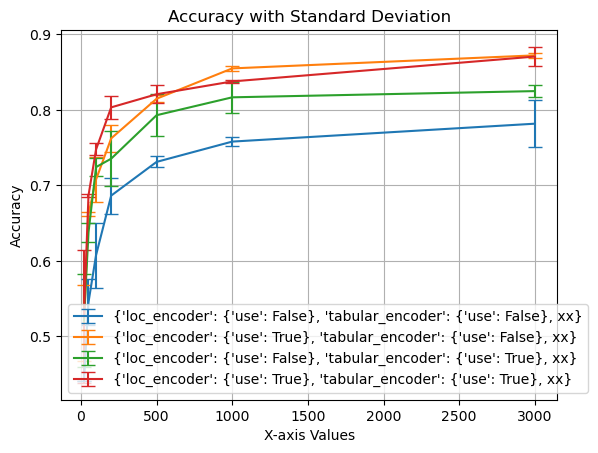

In [55]:
_plot_dict(_models_stats_all, [20, 50, 100, 200, 500, 1000, 3000])

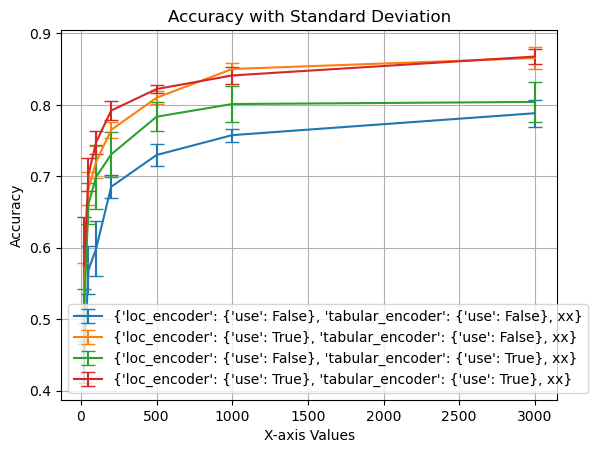

In [207]:
_plot_dict(_models_stats_all, [20, 50, 100, 200, 500, 1000, 3000])

In [220]:
def _plot_dict3(_dict, x_axis_vals):
    x_indices = range(len(x_axis_vals))  # Create equal spacing for x-axis

    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']
        plt.plot(x_indices, acc, label=key)
        plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.2)

    plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('examples per class')
    plt.ylabel('Accuracy')
    #plt.title('Accuracy with Standard Deviation')
    plt.legend()
    plt.grid(True)
    plt.show()

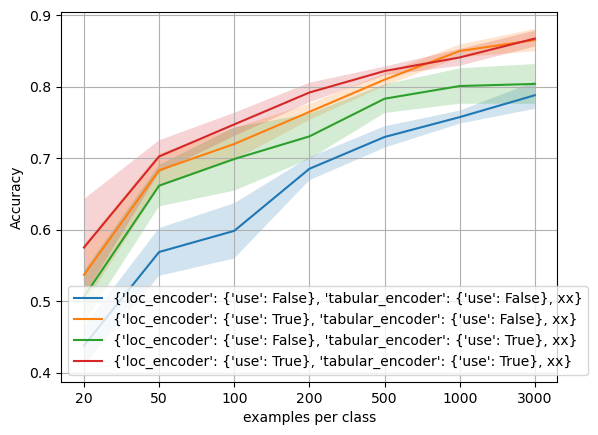

In [221]:
_plot_dict3(_models_stats_all, [20, 50, 100, 200, 500, 1000, 3000])

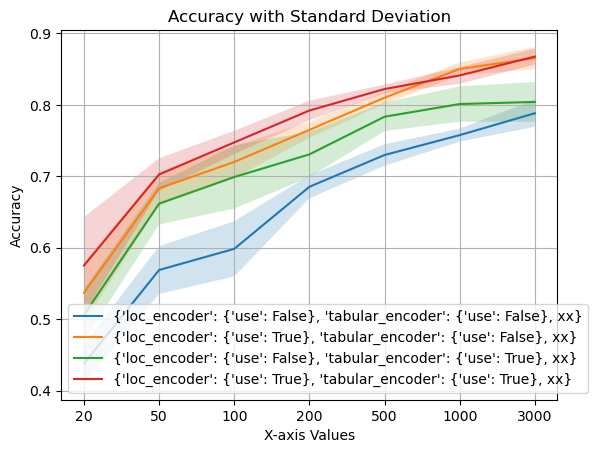

In [209]:
_plot_dict3(_models_stats_all, [20, 50, 100, 200, 500, 1000, 3000])

In [210]:

def _plot_dict4(_dict, x_axis_vals):
    x_indices = range(len(x_axis_vals))  # Create equal spacing for x-axis

    for key, value in _dict.items():
        acc = value['acc'][:len(x_axis_vals)]  # Ensure acc length matches x_axis_vals length
        std = value['std'][:len(x_axis_vals)]  # Ensure std length matches x_axis_vals length
        plt.plot(x_indices, acc, label=key)
        plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.2)

    plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('X-axis Values')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

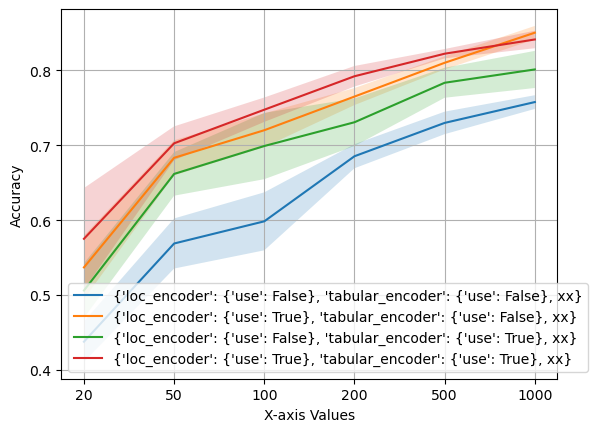

In [211]:
_plot_dict4(_models_stats_all, [20, 50, 100, 200, 500, 1000])

In [218]:
import matplotlib.pyplot as plt
import numpy as np

def _plot_dict5(_dict, x_axis_vals):
    x_indices = np.arange(len(x_axis_vals))  # Create equal spacing for x-axis
    bar_width = 0.13  # Width of the bars
    n_models = len(_dict)
    offset = np.linspace(-bar_width * (n_models - 1) / 2, bar_width * (n_models - 1) / 2, n_models)

    plt.figure(figsize=(12,6)) 
    
    for i, (key, value) in enumerate(_dict.items()):
        acc = value['acc'][:len(x_axis_vals)]  # Ensure acc length matches x_axis_vals length
        std = value['std'][:len(x_axis_vals)]  # Ensure std length matches x_axis_vals length
        plt.bar(x_indices + offset[i], acc, width=bar_width, label=key, yerr=std, capsize=5)

    plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('N examples per class')
    plt.ylabel('Accuracy')
    #plt.title('Accuracy with Standard Deviation')
    plt.legend()
    plt.ylim(bottom=0)
    plt.ylim(top=1.1)
    plt.grid(True)
    plt.show()

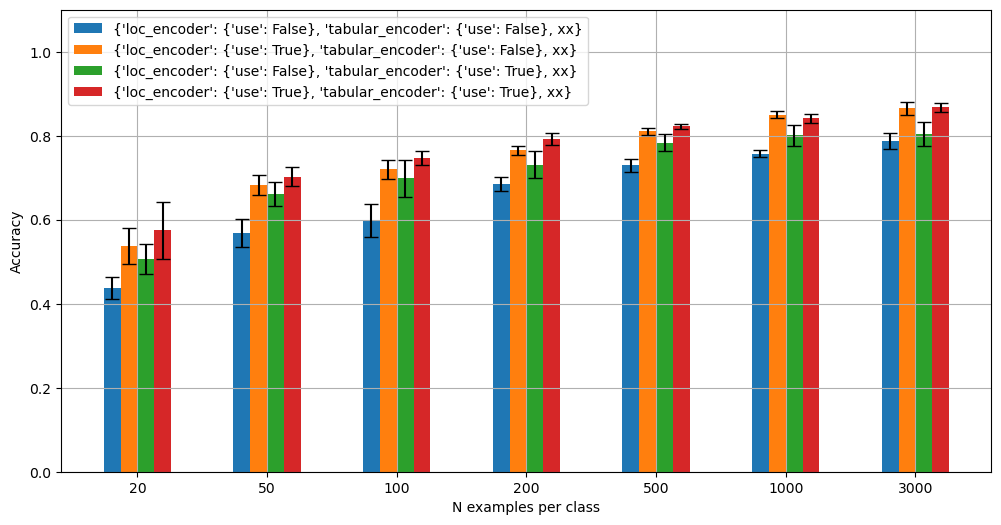

In [219]:
_plot_dict5(_models_stats_all, [20, 50, 100, 200, 500, 1000, 3000])

In [222]:


from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [223]:
countries = ['Costa Rica', 'Ghana', 'Cambodia']


In [224]:
model = models[0]
_country = 'Costa Rica'
country_indices = labels.loc[labels.country == _country].index.tolist()
country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
country_predictions = model['predictions'][country_indices]

_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)
pd.DataFrame(_metrics)

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,micro avg,macro avg,weighted avg
precision,0.0,0.0,0.0,1.000000,0.895735,0.500000,0.923077,0.0,0.0,0.105263,0.0,0.0,0.767361,0.285340,0.900331
recall,0.0,0.0,0.0,0.125000,0.870968,1.000000,0.923077,0.0,0.0,0.500000,0.0,0.0,0.767361,0.284920,0.767361
f1-score,0.0,0.0,0.0,0.222222,0.883178,0.666667,0.923077,0.0,0.0,0.173913,0.0,0.0,0.767361,0.239088,0.784378
support,0.0,0.0,0.0,40.000000,217.000000,1.000000,26.000000,0.0,0.0,4.000000,0.0,0.0,288.000000,288.000000,288.000000


In [ ]:
'''
xx = labels.loc[labels['split'] == 4 ]
xx['preds'] = model_dict['predictions']
xx['preds'] = xx.preds.map(inverse_label_mapping)
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv")
xx['correct'] = xx.driver == xx.preds

xx['geometry'] = gpd.GeoSeries.from_wkt(xx['geometry'])
xx = gpd.GeoDataFrame(xx)
xx.crs = 4326

xx.to_file('../data/tmp/preds.gpkg')
'''

# Compute metrics per country

### Classification report outputs
The reported averages include macro average (averaging the unweighted mean per label), weighted average (averaging the support-weighted mean per label), and sample average (only for multilabel classification). \

**Micro average (averaging the total true positives, false negatives and false positives) is only shown for multi-label or multi-class with a subset of classes, because it corresponds to accuracy otherwise and would be the same for all metrics.**

In [282]:
countries = ['Costa Rica', 'Ghana', 'Cambodia', 'rest']


performance_per_configuration_per_country = {}



for _country in countries:
    if _country == 'rest':
        country_indices = labels.loc[~labels.country.isin(['Costa Rica', 'Ghana', 'Cambodia'])].index.tolist()
        country_targets =  labels.loc[~labels.country.isin(['Costa Rica', 'Ghana', 'Cambodia'])].driver.map(LABEL_MAPPING).to_numpy()
            
    else:
        country_indices = labels.loc[labels.country == _country].index.tolist()
        country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
    
    performance_per_configuration_per_country[_country] = {}


    for combo in combinations:

        metrics_per_random_seed = []
        combo_str = ' '.join(pformat(combo, width=1).split())
        combo_str = remove_seed(combo_str)

        #Compute metrics per each random seed separately
        for seed in hyperparams_values['seed']:
            combo['seed'] = seed 

            #Get all models that have the configuration setup 
            model_with_this_config = get_models_with_config(models, combo)
            if not model_with_this_config:
                continue

            assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
            model_with_this_config = model_with_this_config[0]
            if not 'predictions' in model_with_this_config.keys():
                continue

            country_predictions = model_with_this_config['predictions'][country_indices]
            country_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)


            metrics_per_random_seed.append(pd.DataFrame(country_metrics))

        if not metrics_per_random_seed:
            print("no metrics for: ", combo)
            continue


        # Concatenate DataFrames along a new axis
        concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

        # Compute the mean along the new axis
        mean_df = concat_df.groupby(level=1).mean()

        # Compute the standard deviation along the new axis
        std_df = concat_df.groupby(level=1).std()   



        performance_per_configuration_per_country[_country][combo_str] = {}
        performance_per_configuration_per_country[_country][combo_str]['mean'] = mean_df
        performance_per_configuration_per_country[_country][combo_str]['std'] = std_df



        
        

In [261]:
key = "{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}"
performance_per_configuration_per_country['Ghana'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,accuracy,macro avg,weighted avg,micro avg
f1-score,0.0,0.0,0.0,0.0,0.359574,0.753395,0.852771,0.935584,0.0,0.296016,0.0,0.0,0.892473,0.266445,0.902167,0.8567
precision,0.0,0.0,0.0,0.0,0.351767,0.877990,0.825864,0.977933,0.0,0.191385,0.0,0.0,0.892473,0.268745,0.950678,0.8567
recall,0.0,0.0,0.0,0.0,0.390909,0.675758,0.896552,0.897266,0.0,0.900000,0.0,0.0,0.892473,0.313374,0.863854,0.8567
support,0.0,0.0,0.0,0.0,22.000000,132.000000,29.000000,1024.000000,0.0,2.000000,0.0,0.0,0.892473,1209.000000,1209.000000,1209.0000


In [268]:
for key, value in performance_per_configuration_per_country['Ghana'].items():
    print(val)

["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}"]['mean']



In [267]:
for key, value in performance_per_configuration_per_country['Cambodia'].items():
    print(key)
    print(value['mean'].keys())

{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'weighted avg', 'micro avg'],
      dtype='object')
{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 1000}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'weighted avg', 'micro avg'],
      dtype='object')
{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'wei

In [287]:
def process_stats_country(___models, metric='accuracy'):

    _models_stats = {}
    
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in [20, 50, 100, 200, 500, 1000, 3000]:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_examples_per_class': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_examples_per_class': {n_examples}") 
            sel_model = selected_models[model_name]
            try:
                acc = sel_model['mean'][metric]['f1-score']
                std = sel_model['std'][metric]['f1-score']
            except KeyError:
                acc = sel_model['mean']['accuracy']['f1-score']
                std = sel_model['std']['accuracy']['f1-score']                
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)


        
    return _models_stats
    

In [288]:
#costa_rica = process_stats_all(performance_per_configuration_per_country['Costa Rica'], metric='micro avg')
ghana = process_stats_country(performance_per_configuration_per_country['Ghana'], metric='micro avg')
#cambodia = process_stats_country(performance_per_configuration_per_country['Cambodia'], metric='micro avg')

In [289]:
rest = process_stats_country(performance_per_configuration_per_country['rest'], metric='micro avg')

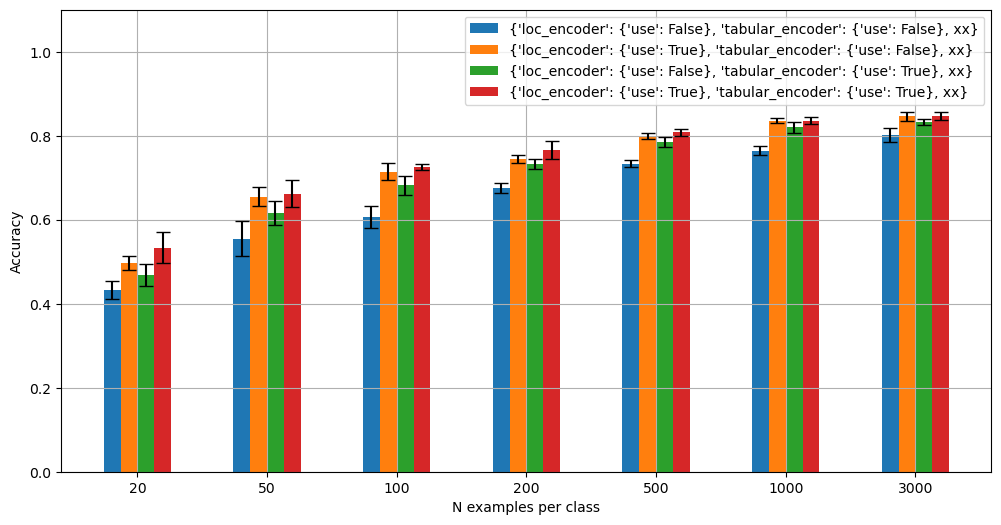

In [290]:
_plot_dict5(rest, [20, 50, 100, 200, 500, 1000, 3000])

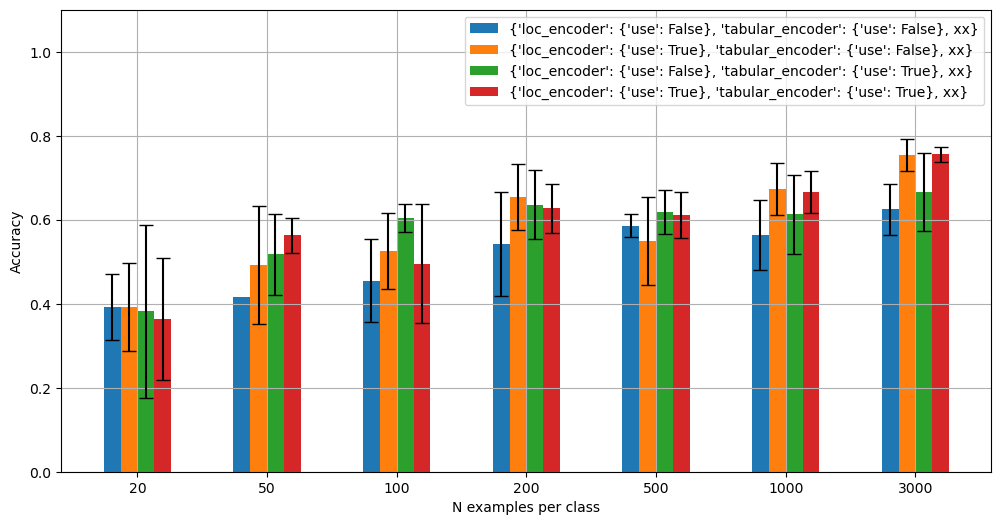

In [281]:
_plot_dict5(costa_rica, [20, 50, 100, 200, 500, 1000, 3000])

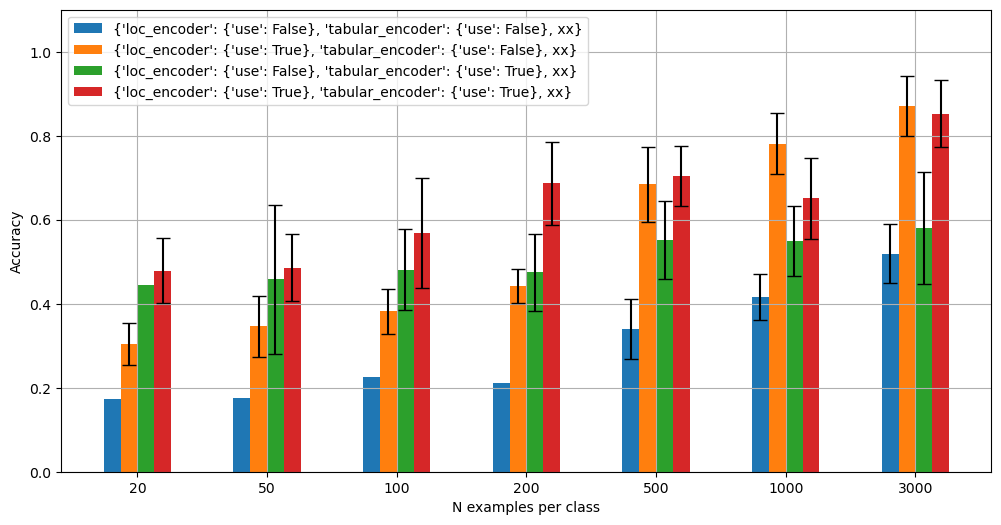

In [278]:
_plot_dict5(cambodia, [20, 50, 100, 200, 500, 1000, 3000])

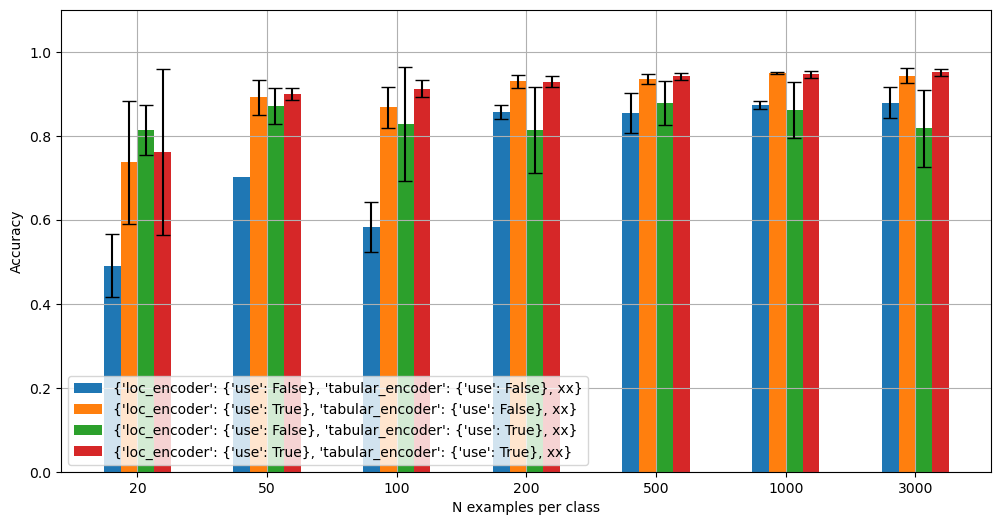

In [280]:
_plot_dict5(ghana, [20, 50, 100, 200, 500, 1000, 3000])

In [72]:
_country = "Cambodia"
models_100_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 100}" in key}
models_500_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 500}" in key}


In [ ]:
_plot_dict4(_models_stats_all, [20, 50, 100, 200, 500, 1000])

In [73]:
list(models_100_per_class_country.keys())

["{'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}",
 "{'seed': 425, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 100}"]

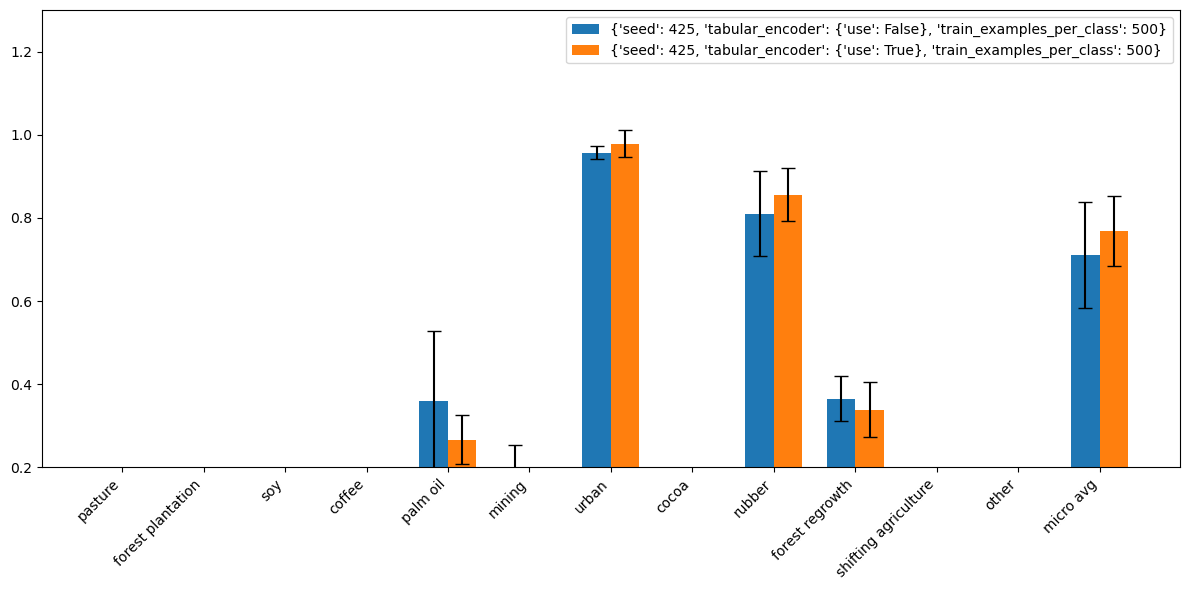

In [77]:
plot_metrics(models_500_per_class_country, metric='micro avg', ylim=(0.2,1.3))


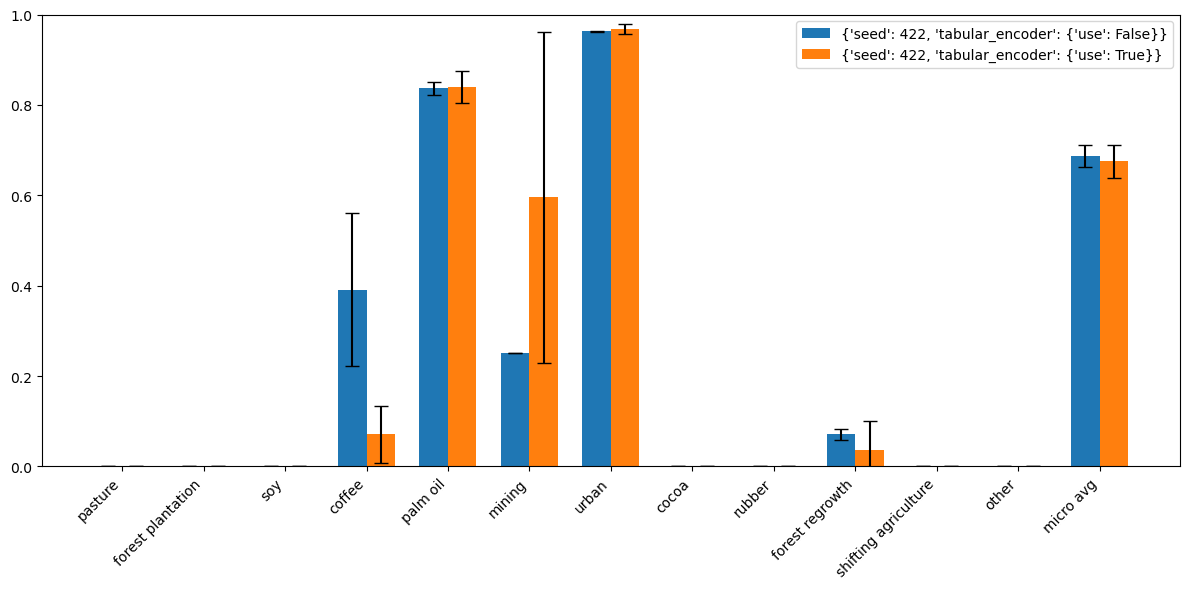

In [31]:
plot_metrics(performance_per_configuration_per_country['Costa Rica'], metric='micro avg', ylim=(0,1))


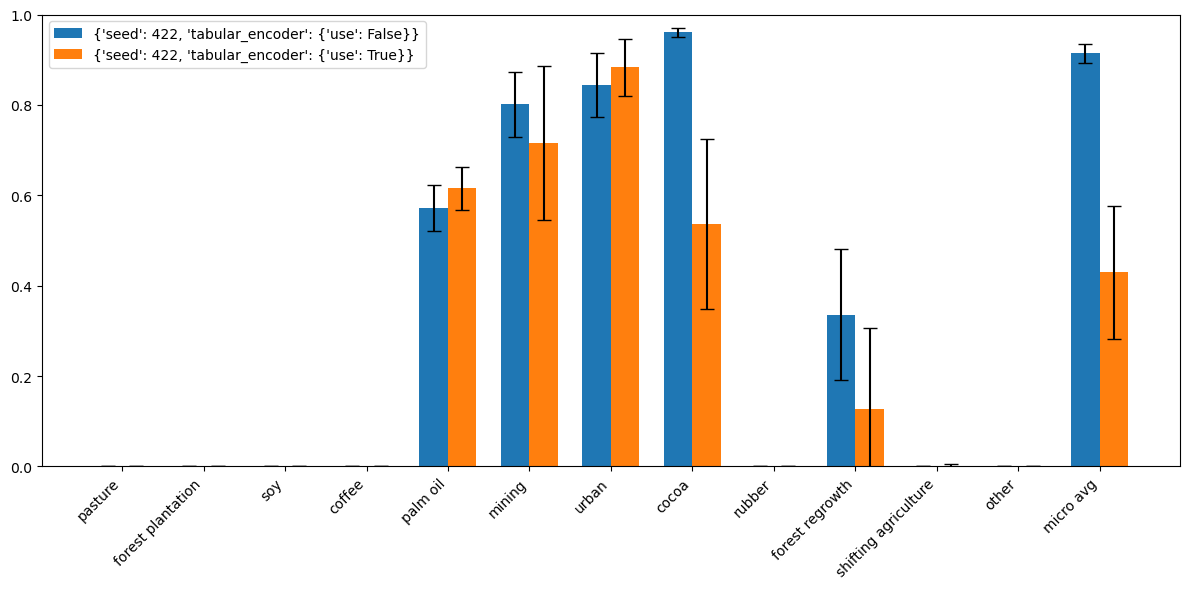

In [30]:
plot_metrics(performance_per_configuration_per_country['Ghana'], metric='micro avg', ylim=(0,1))


In [46]:
labels['model2_pred'] = models[2]['predictions']
labels['model2_pred'] = labels['model2_pred'].map(inverse_label_mapping)

In [55]:
labels['model_1_correct'] = labels.driver == labels.model1_pred
labels['model_2_correct'] = labels.driver == labels.model2_pred

In [56]:
#labels['geometry'] = gpd.GeoSeries.from_wkt(labels['geometry'])
gpd.GeoDataFrame(labels).to_file('../data/tmp/preds.gpkg')

In [57]:
labels

,driver,sampleid,dataset,country,geometry,block_id,split,model1_pred,model2_pred,model_1_correct,model_2_correct
0,coffee,190000083,manual_annotation.csv,Costa Rica,POINT (-84.25407 10.14892),92.0,4,coffee,mining,True,False
1,coffee,190000084,manual_annotation.csv,Costa Rica,POINT (-84.37103 10.14003),92.0,4,palm oil,cocoa,False,False
2,coffee,190000085,manual_annotation.csv,Costa Rica,POINT (-84.38558 10.13114),92.0,4,palm oil,cocoa,False,False
3,coffee,190000086,manual_annotation.csv,Costa Rica,POINT (-84.32467 10.11335),92.0,4,cocoa,cocoa,False,False
4,coffee,190000087,manual_annotation.csv,Costa Rica,POINT (-84.40768 10.05999),92.0,4,palm oil,cocoa,False,False
...,...,...,...,...,...,...,...,...,...,...,...
5072,forest plantation,10655614,mapbiomas.csv,Brazil,POINT (-42.75639 -19.48473),33.0,4,forest plantation,coffee,True,False
5073,forest plantation,10655563,mapbiomas.csv,Brazil,POINT (-42.41844 -19.46694),33.0,4,forest plantation,forest plantation,True,True
5074,forest plantation,10656797,mapbiomas.csv,Brazil,POINT (-43.34335 -19.97386),33.0,4,forest plantation,forest plantation,True,True
5075,forest plantation,10653072,mapbiomas.csv,Brazil,POINT (-42.43623 -18.53314),33.0,4,forest plantation,forest plantation,True,True


In [40]:
models[2]['predictions']

{'seed': 421,
 'epochs': 75,
 'batch_size': 64,
 'classifier': {'type': 'transformer',
  'attention_heads': 8,
  'transformer_layers': 3},
 'in_channels': 4,
 'loc_encoder': {'use': True, 'positional_embedding': 'cartesian3d'},
 'n_parameters': 13160333,
 'val_dst_size': 5077,
 'weight_decay': 0.002,
 'embedding_dim': 128,
 'image_encoder': {'use': True,
  'type': 'cnn',
  'backbone': 'resnet18',
  'moco_weights': False,
  'freezing_patience': 4,
  'pretrained_backbone': True},
 'learning_rate': 0.0005,
 'model_version': 'v1',
 'folds_to_split': {'column': 'split',
  'mapping': {'0': 'train',
   '1': 'train',
   '2': 'train',
   '3': 'train',
   '4': 'val'}},
 'train_dst_size': 6000,
 'use_forestloss': True,
 'tabular_encoder': {'use': True,
  'type': 'token',
  'dataset': 'deduce',
  'temporal_processing': 'dynamic'},
 'randomize_labels': False,
 'forestloss_params': {'sigma': 6, 'kernel_size': 15, 'apply_after_layer': 3},
 'early_stopping_patience': 75,
 'train_examples_per_class': 5

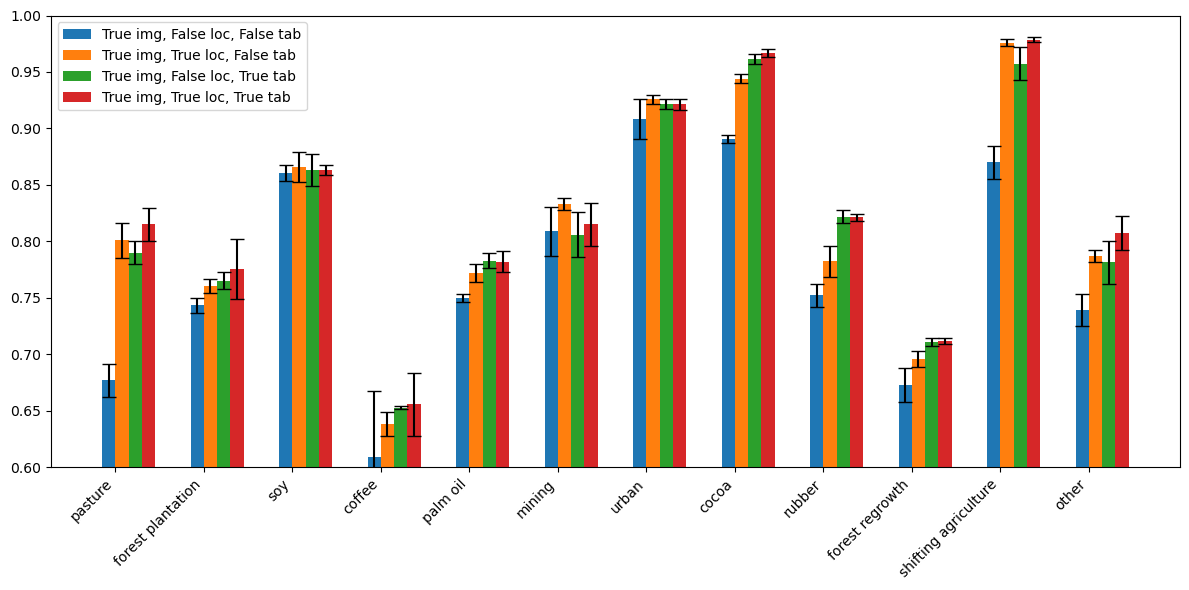

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

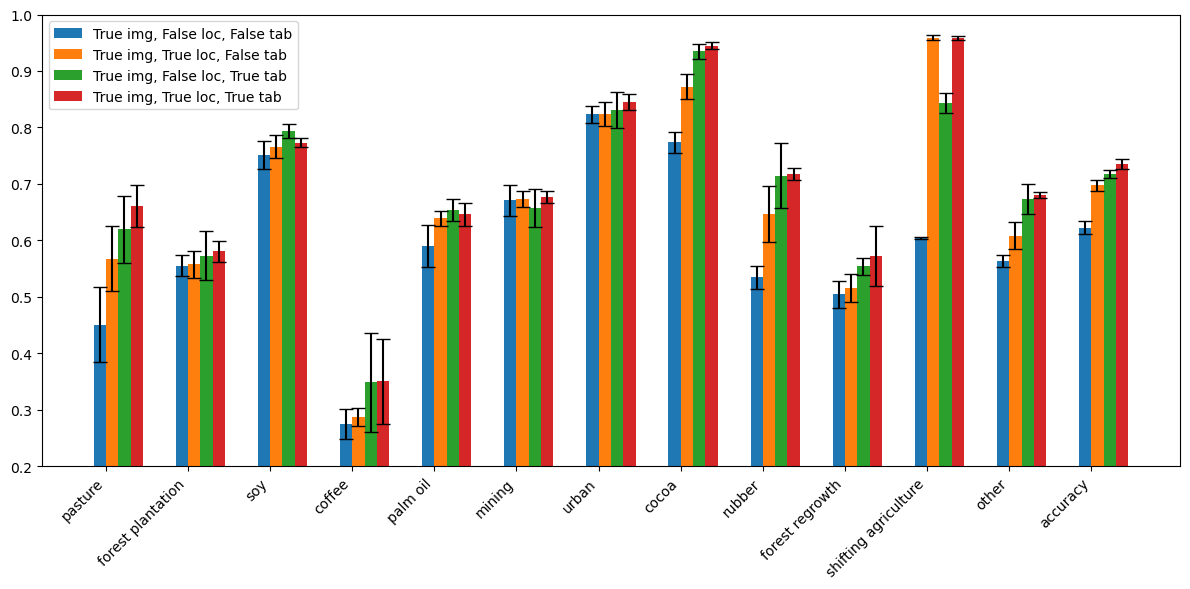

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [79]:
xx = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv')

In [82]:
xx.dataset.value_counts()

dataset
mapbiomas.csv                     6481
mapbiomas_indonesia.csv           3552
rubber.csv                        2996
vancutsem_regrowth.csv            2975
tyukavina_congo_basin_agri.csv    2821
mines.csv                         2486
worldcover.csv                    2429
palm_oil.csv                      2320
cocoa.csv                         2219
soy_south_america.csv             2144
cocoa_ecuador.csv                  656
mapbiomas_peru.csv                 585
manual_annotation.csv              405
mapbiomas_paraguay.csv             405
colombia_pasture.csv               298
coffee_maskell.csv                 283
mapbiomas_bolivia.csv              237
africa_masolele.csv                194
cocoa_peru_points.csv               44
coffee_sdpt_brazil.csv              41
mapbiomas_venezuela.csv             34
Name: count, dtype: int64

In [89]:
xx.loc[xx.dataset != 'africa_masolele.csv'].to_csv('../data/labels/dataset_v5/labels_grid_5_split_no_masolele.csv', index=False)

In [88]:
xx

,driver,sampleid,dataset,country,geometry,block_id,split
0,cocoa,170000000,cocoa_peru_points.csv,Peru,POINT (-78.1800924591649 -4.4448238378139076),66.0,0
1,cocoa,170000002,cocoa_peru_points.csv,Peru,POINT (-76.32138830479319 -6.303527986575525),67.0,3
2,cocoa,170000003,cocoa_peru_points.csv,Peru,POINT (-76.11684191459916 -6.312421307861641),67.0,3
3,cocoa,170000004,cocoa_peru_points.csv,Peru,POINT (-75.77000238340061 -6.347994593006127),67.0,3
4,cocoa,170000005,cocoa_peru_points.csv,Peru,POINT (-76.0545886654097 -6.365781235578377),67.0,3
...,...,...,...,...,...,...,...
33600,forest plantation,10698584,mapbiomas.csv,Brazil,POINT (-50.31072642972264 -30.155633046502274),14.0,0
33601,forest plantation,80063592,mapbiomas_indonesia.csv,Indonesia,POINT (102.87698944468539 0.6374894394167583),202.0,3
33602,forest plantation,10686066,mapbiomas.csv,Brazil,POINT (-49.310767598259304 -22.112163750390017),32.0,3
33603,forest plantation,10649958,mapbiomas.csv,Brazil,POINT (-41.58247137745064 -15.758425504011205),46.0,0
